## Section 1: Setup & Imports

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import soundfile as sf
import tensorflow as tf

from src.utils.config import *
from src.data.loader import (
    load_metadata,
    create_splits,
    save_split_metadata,
)
from src.data.preprocessing import (
    load_audio,
    get_audio_info,
    normalize_audio,
    extract_mel_spectrogram,
    fix_length_frames,
    preprocess_single,
)
from src.features.audio_features import (
    plot_waveform,
    plot_mel_spectrogram,
    plot_comparison,
)

plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {len(tf.config.list_physical_devices('GPU')) > 0}")
print_config()

TensorFlow version: 2.21.0
GPU available: False
Dysarthria AI — Configuration
Project Root:       E:\speech disorder gp
Raw Data Dir:       E:\speech disorder gp\data\raw
UASpeech Audio Dir: E:\speech disorder gp\data\raw\UASpeech\audio\noisereduce
Metadata Dir:       E:\speech disorder gp\data\metadata
Figures Dir:        E:\speech disorder gp\outputs\figures

Target Sample Rate: 16000 Hz
N Mels:             128
N FFT:              2048
Hop Length:         512
Max Duration:       5.0 sec
Target Frames:      157
Input Shape:        (128, 157, 1)

Train Blocks:       ['B1', 'B3']
Test Blocks:        ['B2']
Val Speaker Frac:   0.15
Random Seed:        42
Batch Size:         32


## Section 2: Load Metadata

In [ ]:
# Load metadata from Phase 1
metadata_df = load_metadata()
print(f"Loaded {len(metadata_df)} records")
print(f"Columns: {list(metadata_df.columns)}")
metadata_df.head()
metadata_df.info()

Loaded metadata from E:\speech disorder gp\data\metadata\uaspeech_metadata.csv (143290 rows)
Loaded 143290 records
Columns: ['filepath', 'filename', 'speaker', 'block', 'word', 'microphone', 'label', 'label_name']


,filepath,filename,speaker,block,word,microphone,label,label_name
0,E:\speech disorder gp\data\raw\UASpeech\audio\...,CF02_B1_C10_M2.wav,CF02,B1,C10,M2,0,Control
1,E:\speech disorder gp\data\raw\UASpeech\audio\...,CF02_B1_C10_M3.wav,CF02,B1,C10,M3,0,Control
2,E:\speech disorder gp\data\raw\UASpeech\audio\...,CF02_B1_C10_M4.wav,CF02,B1,C10,M4,0,Control
3,E:\speech disorder gp\data\raw\UASpeech\audio\...,CF02_B1_C10_M5.wav,CF02,B1,C10,M5,0,Control
4,E:\speech disorder gp\data\raw\UASpeech\audio\...,CF02_B1_C10_M6.wav,CF02,B1,C10,M6,0,Control


In [17]:
print(metadata_df['label_name'].value_counts())

label_name
Dysarthric    73675
Control       69615
Name: count, dtype: int64


In [ ]:
metadata_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 143290 entries, 0 to 143289
Data columns (total 8 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   filepath    143290 non-null  str  
 1   filename    143290 non-null  str  
 2   speaker     143290 non-null  str  
 3   block       143290 non-null  str  
 4   word        143290 non-null  str  
 5   microphone  143290 non-null  str  
 6   label       143290 non-null  int64
 7   label_name  143290 non-null  str  
dtypes: int64(1), str(7)
memory usage: 8.7 MB


## Section 3: Inspect Sampling Rates
Before setting preprocessing parameters, let's verify the actual sampling rates in the dataset.

In [3]:
import random
random.seed(RANDOM_SEED)

# Sample 200 files to check sampling rates
sample_size = min(200, len(metadata_df))
sampled = metadata_df.sample(sample_size, random_state=RANDOM_SEED)

sr_set = set()
for _, row in sampled.iterrows():
    info = get_audio_info(row['filepath'])
    sr_set.add(info['sample_rate'])

print(f"Unique sampling rates found (from {sample_size} files): {sr_set}")

if len(sr_set) == 1:
    native_sr = sr_set.pop()
    print(f"\n\u2713 Dataset uses a consistent sampling rate: {native_sr} Hz")
    if native_sr == TARGET_SAMPLE_RATE:
        print(f"\u2713 Matches TARGET_SAMPLE_RATE ({TARGET_SAMPLE_RATE} Hz) — no resampling needed")
    else:
        print(f"\u26a0 Native rate ({native_sr} Hz) differs from TARGET_SAMPLE_RATE ({TARGET_SAMPLE_RATE} Hz)")
        print(f"  Resampling will be applied during preprocessing")
else:
    print(f"\n\u26a0 Multiple sampling rates found: {sr_set}")
    print(f"  All files will be resampled to {TARGET_SAMPLE_RATE} Hz")

Unique sampling rates found (from 200 files): {16000}

✓ Dataset uses a consistent sampling rate: 16000 Hz
✓ Matches TARGET_SAMPLE_RATE (16000 Hz) — no resampling needed


## Section 4: Duration Statistics
Compute duration statistics to determine the fixed spectrogram size.

Duration Statistics (seconds):
  Min:       1.153
  Max:       15.140
  Mean:      2.584
  Median:    2.095
  Std Dev:   1.771
  95th pct:  5.602
  99th pct:  10.298

Current MAX_DURATION_SEC: 5.0 sec
Current TARGET_FRAMES:   157
Current INPUT_SHAPE:     (128, 157, 1)


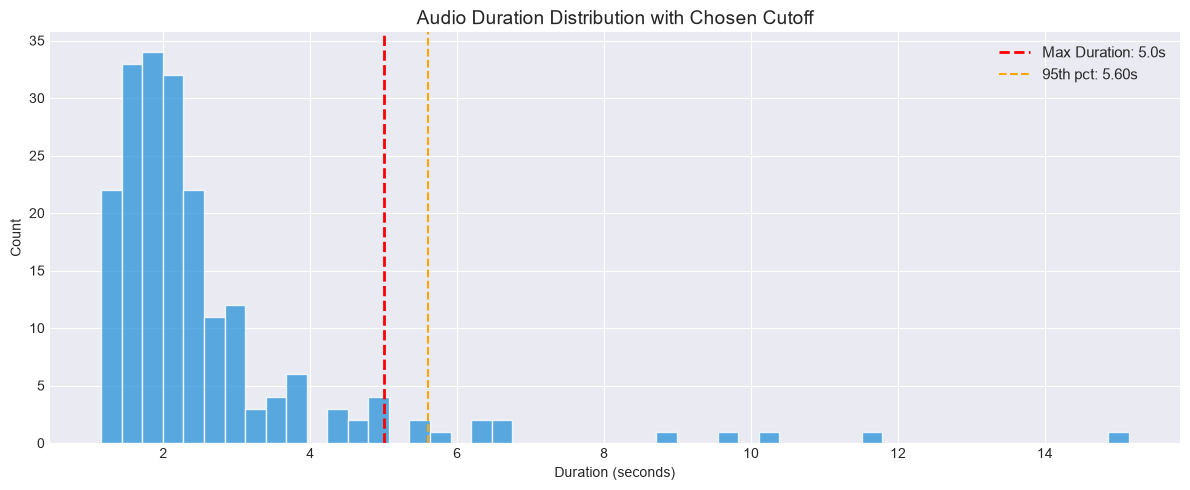


94.0% of samples are <= 5.0 seconds (will not be cropped)


In [4]:
# Compute durations from metadata sample
durations = []
for _, row in sampled.iterrows():
    info = get_audio_info(row['filepath'])
    durations.append(info['duration'])

durations = np.array(durations)

print("Duration Statistics (seconds):")
print(f"  Min:       {durations.min():.3f}")
print(f"  Max:       {durations.max():.3f}")
print(f"  Mean:      {durations.mean():.3f}")
print(f"  Median:    {np.median(durations):.3f}")
print(f"  Std Dev:   {durations.std():.3f}")
print(f"  95th pct:  {np.percentile(durations, 95):.3f}")
print(f"  99th pct:  {np.percentile(durations, 99):.3f}")

print(f"\nCurrent MAX_DURATION_SEC: {MAX_DURATION_SEC} sec")
print(f"Current TARGET_FRAMES:   {TARGET_FRAMES}")
print(f"Current INPUT_SHAPE:     {INPUT_SHAPE}")

# Duration histogram
fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(durations, bins=50, color='#3498db', edgecolor='white', alpha=0.8)
ax.axvline(MAX_DURATION_SEC, color='red', linestyle='--', linewidth=2, label=f'Max Duration: {MAX_DURATION_SEC}s')
ax.axvline(np.percentile(durations, 95), color='orange', linestyle='--', label=f'95th pct: {np.percentile(durations, 95):.2f}s')
ax.set_title('Audio Duration Distribution with Chosen Cutoff', fontsize=14)
ax.set_xlabel('Duration (seconds)')
ax.set_ylabel('Count')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'duration_vs_cutoff.png', dpi=150, bbox_inches='tight')
plt.show()

pct_covered = (durations <= MAX_DURATION_SEC).mean() * 100
print(f"\n{pct_covered:.1f}% of samples are <= {MAX_DURATION_SEC} seconds (will not be cropped)")

## Section 5: Mel Spectrogram Visualization
Visualize Mel Spectrograms for representative Control and Dysarthric samples.

Control sample: CF02_B1_C10_M2.wav
  Audio length: 29533 samples (1.846 sec)
  Mel spec shape: (128, 58)
Dysarthric sample: F02_B1_C10_M2.wav
  Audio length: 70144 samples (4.384 sec)
  Mel spec shape: (128, 138)


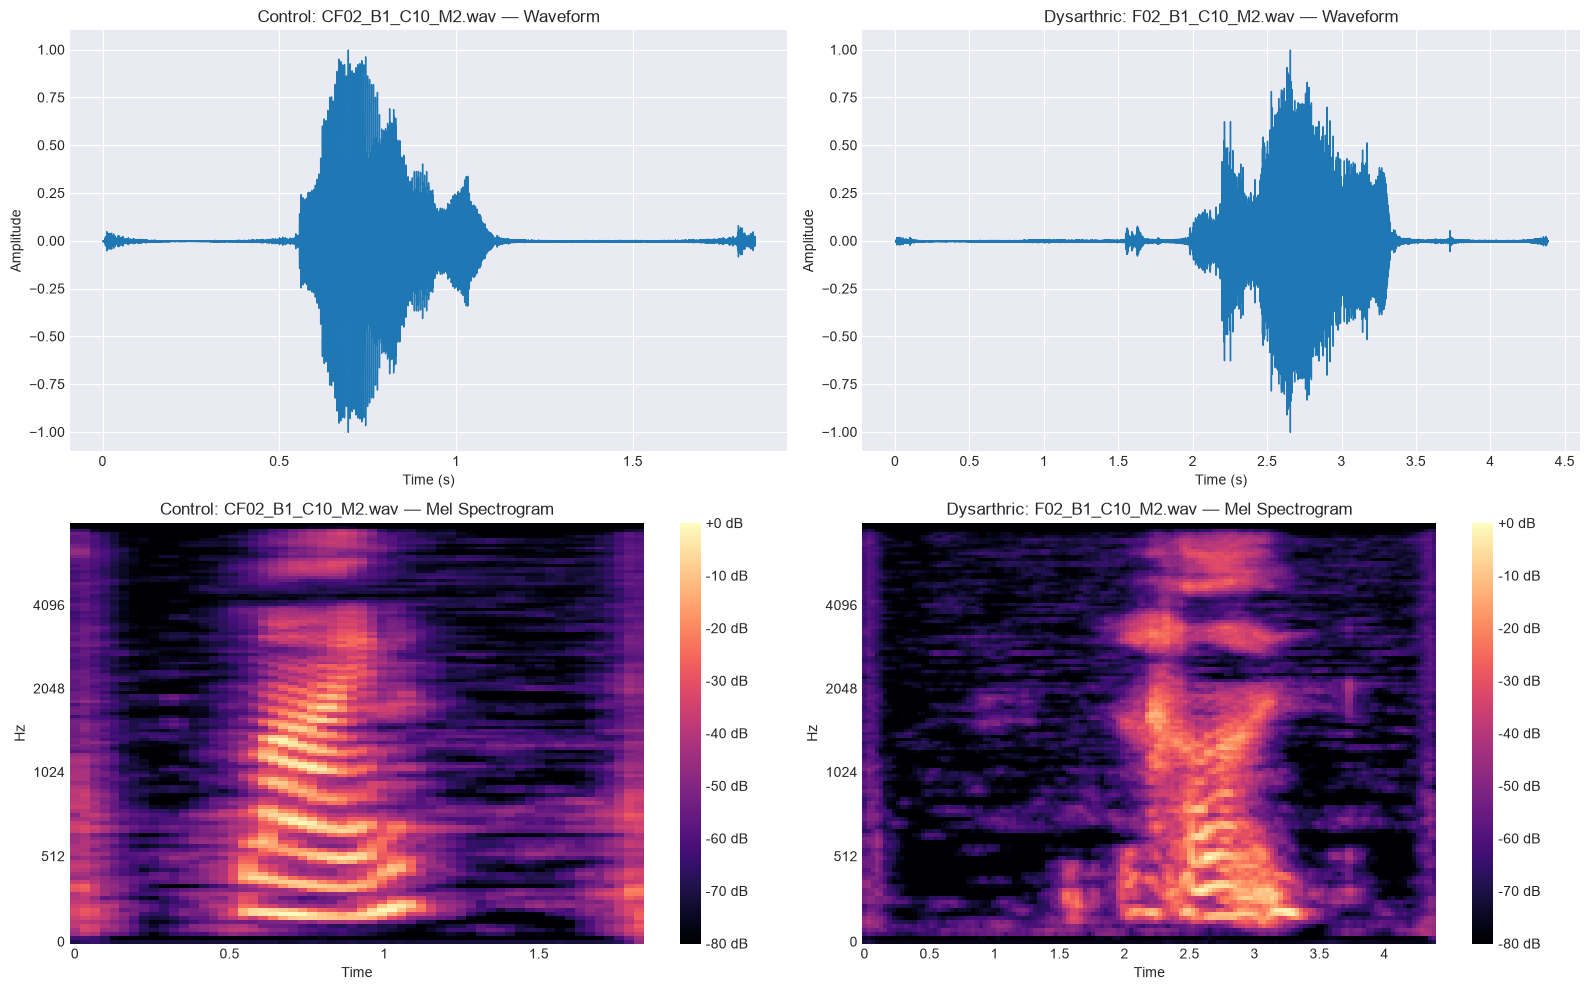

In [6]:
# Select one control and one dysarthric sample
control_row = metadata_df[metadata_df['label'] == 0].iloc[0]
dysarthric_row = metadata_df[metadata_df['label'] == 1].iloc[0]

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for col, (row, label) in enumerate([(control_row, 'Control'), (dysarthric_row, 'Dysarthric')]):
    # Load audio
    audio, sr = load_audio(row['filepath'], target_sr=TARGET_SAMPLE_RATE, mono=True)
    audio = normalize_audio(audio)
    
    # Waveform
    plot_waveform(audio, sr, title=f'{label}: {row["filename"]} — Waveform', ax=axes[0, col])
    
    # Mel Spectrogram
    mel_spec = extract_mel_spectrogram(audio, sr)
    plot_mel_spectrogram(mel_spec, sr, title=f'{label}: {row["filename"]} — Mel Spectrogram', ax=axes[1, col])
    
    print(f"{label} sample: {row['filename']}")
    print(f"  Audio length: {len(audio)} samples ({len(audio)/sr:.3f} sec)")
    print(f"  Mel spec shape: {mel_spec.shape}")

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'mel_spectrogram_comparison1.png', dpi=150, bbox_inches='tight')
plt.show()

## Section 6: Test Full Preprocessing Pipeline
Test the complete preprocessing pipeline on a few samples.

In [7]:
# Test preprocessing on several samples
test_files = pd.concat([
    metadata_df[metadata_df['label'] == 0].sample(3, random_state=42),
    metadata_df[metadata_df['label'] == 1].sample(3, random_state=42),
])

print(f"Testing preprocessing pipeline on {len(test_files)} files...")
print(f"Expected output shape: {INPUT_SHAPE}")
print()

for _, row in test_files.iterrows():
    try:
        tensor = preprocess_single(row['filepath'])
        print(f"\u2713 {row['filename']:30s} | shape: {tensor.shape} | "
              f"dtype: {tensor.dtype} | min: {tensor.min():.2f} | max: {tensor.max():.2f} | "
              f"has_nan: {np.isnan(tensor).any()} | has_inf: {np.isinf(tensor).any()}")
    except Exception as e:
        print(f"\u2717 {row['filename']:30s} | ERROR: {e}")

Testing preprocessing pipeline on 6 files...
Expected output shape: (128, 157, 1)

✓ CM06_B3_UW89_M7.wav            | shape: (128, 157, 1) | dtype: float32 | min: -80.00 | max: 0.00 | has_nan: False | has_inf: False
✓ CF03_B2_CW2_M6.wav             | shape: (128, 157, 1) | dtype: float32 | min: -80.00 | max: 0.00 | has_nan: False | has_inf: False
✓ CF03_B3_LY_M4.wav              | shape: (128, 157, 1) | dtype: float32 | min: -80.00 | max: 0.00 | has_nan: False | has_inf: False
✓ M14_B3_CW60_M7.wav             | shape: (128, 157, 1) | dtype: float32 | min: -80.00 | max: 0.00 | has_nan: False | has_inf: False
✓ M01_B3_LX_M6.wav               | shape: (128, 157, 1) | dtype: float32 | min: -80.00 | max: 0.00 | has_nan: False | has_inf: False
✓ M16_B2_UW84_M3.wav             | shape: (128, 157, 1) | dtype: float32 | min: -80.00 | max: 0.00 | has_nan: False | has_inf: False


## Section 7: Speaker-Independent Data Split
Create speaker-independent train/val/test splits following the standard UASpeech convention: B1+B3 for training, B2 for testing. Validation speakers are held out entirely from training to prevent speaker leakage.

In [8]:
# Create splits
train_df, val_df, test_df = create_splits(metadata_df)

# Save split metadata
save_split_metadata(train_df, val_df, test_df)

Data Split Summary (Speaker-Independent)
Train:   85178 samples | 25 speakers | Blocks: ['B1', 'B3']
Val:     10200 samples |  3 speakers | Blocks: ['B1', 'B3']
Test:    47912 samples | 28 speakers | Blocks: ['B2']

✓ No speaker leakage between train and val
  Train speakers: ['CF02', 'CF03', 'CF04', 'CF05', 'CM01', 'CM04', 'CM05', 'CM06', 'CM08', 'CM09', 'CM10', 'CM13', 'F02', 'F03', 'F04', 'F05', 'M01', 'M04', 'M05', 'M07', 'M08', 'M09', 'M11', 'M14', 'M16']
  Val speakers:   ['CM12', 'M10', 'M12']

  Train class distribution:
    Control: 42840
    Dysarthric: 42338

  Val class distribution:
    Dysarthric: 6630
    Control: 3570

  Test class distribution:
    Dysarthric: 24707
    Control: 23205

Saved Train metadata: E:\speech disorder gp\data\metadata\train_metadata.csv (85178 rows)
Saved Val metadata: E:\speech disorder gp\data\metadata\val_metadata.csv (10200 rows)
Saved Test metadata: E:\speech disorder gp\data\metadata\test_metadata.csv (47912 rows)


## Section 8: TensorFlow Data Pipeline
Build an efficient TensorFlow data pipeline using tf.data.

In [9]:
def create_tf_dataset(file_paths, labels, batch_size=BATCH_SIZE, shuffle=True):
    """Create a tf.data.Dataset from file paths and labels."""
    
    def preprocess_tf(filepath, label):
        """Wrapper to use preprocess_single inside tf.data pipeline."""
        def _preprocess(filepath_bytes, label_val):
            filepath_str = filepath_bytes.numpy().decode('utf-8')
            mel_spec = preprocess_single(filepath_str)
            return mel_spec.astype(np.float32), label_val
        
        mel_spec, label_out = tf.py_function(
            _preprocess,
            [filepath, label],
            [tf.float32, tf.int64],
        )
        mel_spec.set_shape(INPUT_SHAPE)
        label_out.set_shape(())
        return mel_spec, label_out
    
    dataset = tf.data.Dataset.from_tensor_slices((
        file_paths.astype(str),
        labels.astype(np.int64),
    ))
    
    if shuffle:
        dataset = dataset.shuffle(buffer_size=min(len(file_paths), SHUFFLE_BUFFER_SIZE))
    
    dataset = dataset.map(preprocess_tf, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    
    return dataset

print("TensorFlow data pipeline function defined.")
print(f"Batch size: {BATCH_SIZE}")
print(f"Input shape: {INPUT_SHAPE}")

TensorFlow data pipeline function defined.
Batch size: 32
Input shape: (128, 157, 1)


Then test with a small subset:

In [10]:
# Test pipeline with small subset
small_subset = pd.concat([
    train_df[train_df['label'] == 0].head(16),
    train_df[train_df['label'] == 1].head(16),
])

print(f"Testing pipeline with {len(small_subset)} samples...")
test_dataset = create_tf_dataset(
    small_subset['filepath'].values,
    small_subset['label'].values,
    batch_size=8,
    shuffle=False,
)

# Iterate through one batch
for batch_x, batch_y in test_dataset.take(1):
    print(f"\nBatch X shape: {batch_x.shape}")
    print(f"Batch Y shape: {batch_y.shape}")
    print(f"Batch X dtype: {batch_x.dtype}")
    print(f"Batch Y dtype: {batch_y.dtype}")
    print(f"Batch X min:   {tf.reduce_min(batch_x).numpy():.4f}")
    print(f"Batch X max:   {tf.reduce_max(batch_x).numpy():.4f}")
    print(f"Unique labels: {np.unique(batch_y.numpy())}")
    print(f"Has NaN:       {tf.reduce_any(tf.math.is_nan(batch_x)).numpy()}")
    print(f"Has Inf:       {tf.reduce_any(tf.math.is_inf(batch_x)).numpy()}")

print("\n\u2713 TensorFlow pipeline test passed!")

Testing pipeline with 32 samples...

Batch X shape: (8, 128, 157, 1)
Batch Y shape: (8,)
Batch X dtype: <dtype: 'float32'>
Batch Y dtype: <dtype: 'int64'>
Batch X min:   -80.0000
Batch X max:   0.0000
Unique labels: [0]
Has NaN:       False
Has Inf:       False

✓ TensorFlow pipeline test passed!


## Section 9: Build Full Pipelines

In [11]:
# Create full train/val/test datasets
print("Building full datasets...")

train_dataset = create_tf_dataset(
    train_df['filepath'].values,
    train_df['label'].values,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_dataset = create_tf_dataset(
    val_df['filepath'].values,
    val_df['label'].values,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_dataset = create_tf_dataset(
    test_df['filepath'].values,
    test_df['label'].values,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print(f"\n\u2713 Train dataset: {len(train_df)} samples")
print(f"\u2713 Val dataset:   {len(val_df)} samples")
print(f"\u2713 Test dataset:  {len(test_df)} samples")

Building full datasets...

✓ Train dataset: 85178 samples
✓ Val dataset:   10200 samples
✓ Test dataset:  47912 samples


## Section 10: Visualize Batch Spectrograms

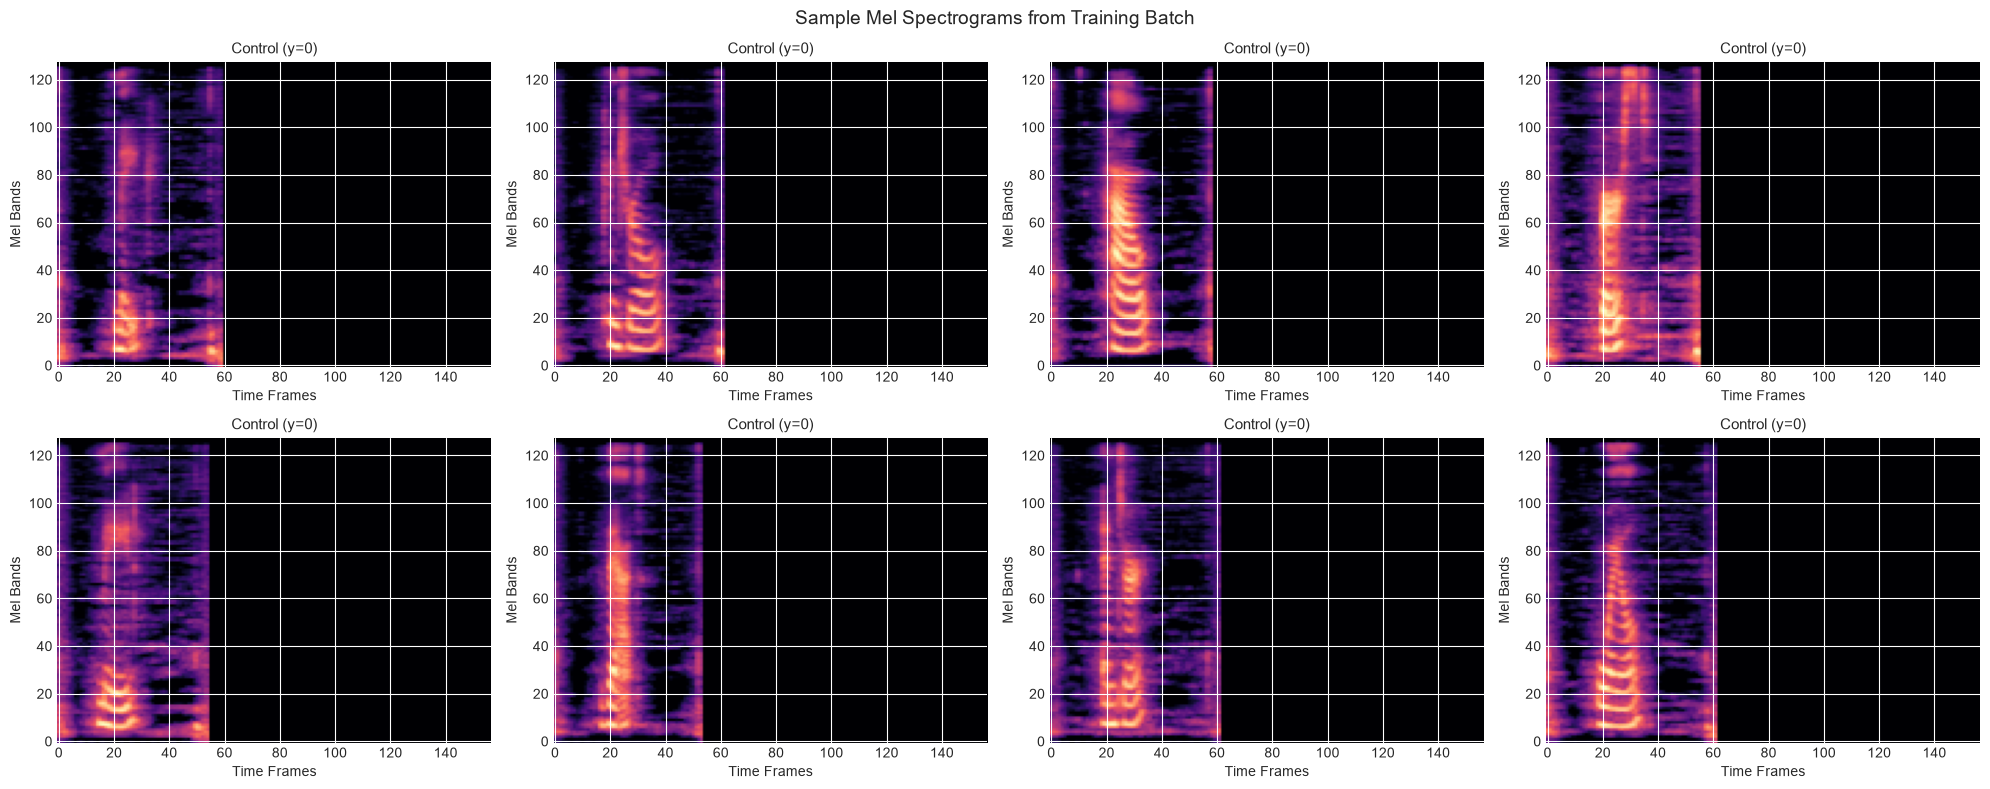

In [12]:
# Visualize spectrograms from a batch
for batch_x, batch_y in train_dataset.take(1):
    fig, axes = plt.subplots(2, 4, figsize=(20, 8))
    for i in range(min(8, batch_x.shape[0])):
        row, col = i // 4, i % 4
        ax = axes[row, col]
        spec = batch_x[i].numpy()[:, :, 0]  # Remove channel dim
        label = batch_y[i].numpy()
        label_name = LABEL_MAP[label]
        
        img = ax.imshow(spec, aspect='auto', origin='lower', cmap='magma')
        ax.set_title(f'{label_name} (y={label})', fontsize=11)
        ax.set_xlabel('Time Frames')
        ax.set_ylabel('Mel Bands')
    
    plt.suptitle('Sample Mel Spectrograms from Training Batch', fontsize=14)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'batch_spectrograms1.png', dpi=150, bbox_inches='tight')
    plt.show()

## Section 11: Sanity Check Baseline Model
A minimal CNN model to verify the data pipeline works end-to-end. This is NOT the final model — just a pipeline verification step.

In [13]:
# Small baseline CNN for sanity check
from tensorflow import keras
from tensorflow.keras import layers

def create_baseline_model(input_shape):
    """Minimal CNN for pipeline verification only."""
    model = keras.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),
        layers.GlobalAveragePooling2D(),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid'),
    ])
    
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy'],
    )
    return model

model = create_baseline_model(INPUT_SHAPE)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 157, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 78, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,889 (23.00 KB)

 Trainable params: 5,889 (23.00 KB)

 Non-trainable params: 0 (0.00 B)

Then train for a few epochs on small subset:

In [14]:
# Train on a SMALL subset for sanity check only
# Using the small test dataset we created earlier
small_train = create_tf_dataset(
    train_df.head(200)['filepath'].values,
    train_df.head(200)['label'].values,
    batch_size=16,
    shuffle=True,
)

small_val = create_tf_dataset(
    val_df.head(64)['filepath'].values,
    val_df.head(64)['label'].values,
    batch_size=16,
    shuffle=False,
)

print("Training baseline model (sanity check only)...")
print("This verifies: data \u2192 preprocessing \u2192 model \u2192 loss \u2192 backprop \u2192 prediction")
print()

history = model.fit(
    small_train,
    validation_data=small_val,
    epochs=3,
    verbose=1,
)

print("\n\u2713 Baseline model training completed successfully!")
print(f"  Final train loss: {history.history['loss'][-1]:.4f}")
print(f"  Final train acc:  {history.history['accuracy'][-1]:.4f}")
if 'val_loss' in history.history:
    print(f"  Final val loss:   {history.history['val_loss'][-1]:.4f}")
    print(f"  Final val acc:    {history.history['val_accuracy'][-1]:.4f}")

Training baseline model (sanity check only)...
This verifies: data → preprocessing → model → loss → backprop → prediction

Epoch 1/3


e:\speech disorder gp\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


13/13 ━━━━━━━━━━━━━━━━━━━━ 10s 341ms/step - accuracy: 0.6550 - loss: 4.3898 - val_accuracy: 1.0000 - val_loss: 3.4663e-14
Epoch 2/3
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 235ms/step - accuracy: 1.0000 - loss: 1.1190e-06 - val_accuracy: 1.0000 - val_loss: 1.0491e-21
Epoch 3/3
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 237ms/step - accuracy: 1.0000 - loss: 6.1442e-10 - val_accuracy: 1.0000 - val_loss: 7.6405e-24

✓ Baseline model training completed successfully!
  Final train loss: 0.0000
  Final train acc:  1.0000
  Final val loss:   0.0000
  Final val acc:    1.0000


Verify predictions:

In [15]:
# Verify predictions
for batch_x, batch_y in small_val.take(1):
    predictions = model.predict(batch_x, verbose=0)
    print(f"Prediction shape: {predictions.shape}")
    print(f"Prediction range: [{predictions.min():.4f}, {predictions.max():.4f}]")
    print(f"True labels:      {batch_y.numpy()[:8]}")
    print(f"Predictions:      {predictions.flatten()[:8].round(3)}")
    print(f"\nAll predictions in [0, 1]: {(predictions >= 0).all() and (predictions <= 1).all()}")
    print(f"Has NaN in predictions: {np.isnan(predictions).any()}")

print("\n" + "=" * 60)
print("\u2713 END-TO-END SANITY CHECK PASSED")
print("=" * 60)
print("\nThe complete pipeline works:")
print("  Dataset \u2192 Metadata \u2192 Labels \u2192 Split \u2192 Audio Loading")
print("  \u2192 Preprocessing \u2192 Mel Spectrogram \u2192 TensorFlow Dataset")
print("  \u2192 Batch Generation \u2192 Model Training \u2192 Predictions")
print("\nReady for CNN-BiLSTM-Attention model implementation!")

Prediction shape: (16, 1)
Prediction range: [0.0000, 0.0000]
True labels:      [0 0 0 0 0 0 0 0]
Predictions:      [0. 0. 0. 0. 0. 0. 0. 0.]

All predictions in [0, 1]: True
Has NaN in predictions: False

✓ END-TO-END SANITY CHECK PASSED

The complete pipeline works:
  Dataset → Metadata → Labels → Split → Audio Loading
  → Preprocessing → Mel Spectrogram → TensorFlow Dataset
  → Batch Generation → Model Training → Predictions

Ready for CNN-BiLSTM-Attention model implementation!


In [19]:
# ============================================
# Verify Labels and Speaker Split
# ============================================

# 1. Check that every speaker has exactly one label
speaker_label_check = (
    metadata_df.groupby("speaker")["label_name"]
    .nunique()
)

print("=" * 60)
print("1. SPEAKER LABEL CONSISTENCY")
print("=" * 60)

if (speaker_label_check == 1).all():
    print("✓ Every speaker has exactly one label.")
else:
    print("⚠️ Some speakers have multiple labels:")
    print(speaker_label_check[speaker_label_check > 1])


# 2. List speakers grouped by label
print("\n" + "=" * 60)
print("2. SPEAKERS BY LABEL")
print("=" * 60)

speakers_by_label = (
    metadata_df.groupby("label_name")["speaker"]
    .unique()
)

for label, speakers in speakers_by_label.items():
    print(f"\n{label} ({len(speakers)} speakers):")
    print(sorted(speakers))


# 3. Number of samples per speaker
print("\n" + "=" * 60)
print("3. SAMPLES PER SPEAKER")
print("=" * 60)

samples_per_speaker = (
    metadata_df.groupby(["label_name", "speaker"])
    .size()
    .sort_index()
)

print(samples_per_speaker)


# 4. Get unique speakers in each split
train_speakers = set(train_df["speaker"].unique())
val_speakers = set(val_df["speaker"].unique())
test_speakers = set(test_df["speaker"].unique())

print("\n" + "=" * 60)
print("4. UNIQUE SPEAKERS PER SPLIT")
print("=" * 60)

print(f"Train:      {len(train_speakers)} speakers")
print(f"Validation: {len(val_speakers)} speakers")
print(f"Test:       {len(test_speakers)} speakers")

print("\nTrain speakers:")
print(sorted(train_speakers))

print("\nValidation speakers:")
print(sorted(val_speakers))

print("\nTest speakers:")
print(sorted(test_speakers))


# 5. Check speaker overlap
train_val_overlap = train_speakers & val_speakers
train_test_overlap = train_speakers & test_speakers
val_test_overlap = val_speakers & test_speakers

print("\n" + "=" * 60)
print("5. SPEAKER OVERLAP")
print("=" * 60)

print(f"Train ∩ Validation: {train_val_overlap}")
print(f"Train ∩ Test:       {train_test_overlap}")
print(f"Validation ∩ Test:  {val_test_overlap}")


# 6. Final interpretation
print("\n" + "=" * 60)
print("6. INTERPRETATION")
print("=" * 60)

if len(train_val_overlap) == 0:
    print("✓ No speaker leakage between Train and Validation.")
else:
    print("⚠️ Speaker overlap exists between Train and Validation.")

if len(train_test_overlap) == 0:
    print("✓ No speaker overlap between Train and Test.")
    print("→ Test is speaker-independent from training.")
else:
    print("⚠️ Speakers are shared between Train and Test.")
    print("→ Current evaluation is NOT truly speaker-independent.")
    print("→ It is a block-based evaluation if Train uses B1/B3 and Test uses B2.")

1. SPEAKER LABEL CONSISTENCY
✓ Every speaker has exactly one label.

2. SPEAKERS BY LABEL

Control (13 speakers):
['CF02', 'CF03', 'CF04', 'CF05', 'CM01', 'CM04', 'CM05', 'CM06', 'CM08', 'CM09', 'CM10', 'CM12', 'CM13']

Dysarthric (15 speakers):
['F02', 'F03', 'F04', 'F05', 'M01', 'M04', 'M05', 'M07', 'M08', 'M09', 'M10', 'M11', 'M12', 'M14', 'M16']

3. SAMPLES PER SPEAKER
label_name  speaker
Control     CF02       5355
            CF03       5355
            CF04       5355
            CF05       5355
            CM01       5355
            CM04       5355
            CM05       5355
            CM06       5355
            CM08       5355
            CM09       5355
            CM10       5355
            CM12       5355
            CM13       5355
Dysarthric  F02        5355
            F03        5184
            F04        5251
            F05        5355
            M01        2805
            M04        3825
            M05        5355
            M07        5355
            M08 